In [114]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory
import matplotlib.pyplot as plt
import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))
import seaborn as sns
# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')

/kaggle/input/datasets/mlomuscio/pokemon/PokemonData.csv
/kaggle/input/datasets/mlomuscio/pokemon/README.md


In [115]:
df = pd.read_csv('../input/datasets/mlomuscio/pokemon/PokemonData.csv')
df.shape

(800, 12)

In [116]:
df.head()

,Num,Name,Type1,Type2,HP,Attack,Defense,SpAtk,SpDef,Speed,Generation,Legendary
0,1,Bulbasaur,Grass,Poison,45,49,49,65,65,45,1,False
1,2,Ivysaur,Grass,Poison,60,62,63,80,80,60,1,False
2,3,Venusaur,Grass,Poison,80,82,83,100,100,80,1,False
3,3,VenusaurMega Venusaur,Grass,Poison,80,100,123,122,120,80,1,False
4,4,Charmander,Fire,NaN,39,52,43,60,50,65,1,False


In [142]:
df.describe(include='all')


,Num,Name,Type1,Type2,HP,Attack,Defense,SpAtk,SpDef,Speed,Generation,Legendary,BST
count,800.000000,800,800,414,800.000000,800.000000,800.000000,800.000000,800.000000,800.000000,800.00000,800,800.00000
unique,NaN,800,18,18,NaN,NaN,NaN,NaN,NaN,NaN,NaN,2,NaN
top,NaN,PumpkabooSuper Size,Water,Flying,NaN,NaN,NaN,NaN,NaN,NaN,NaN,False,NaN
freq,NaN,1,112,97,NaN,NaN,NaN,NaN,NaN,NaN,NaN,735,NaN
mean,362.813750,NaN,NaN,NaN,69.258750,79.001250,73.842500,72.820000,71.902500,68.277500,3.32375,NaN,435.10250
std,208.343798,NaN,NaN,NaN,25.534669,32.457366,31.183501,32.722294,27.828916,29.060474,1.66129,NaN,119.96304
min,1.000000,NaN,NaN,NaN,1.000000,5.000000,5.000000,10.000000,20.000000,5.000000,1.00000,NaN,180.00000
25%,184.750000,NaN,NaN,NaN,50.000000,55.000000,50.000000,49.750000,50.000000,45.000000,2.00000,NaN,330.00000
50%,364.500000,NaN,NaN,NaN,65.000000,75.000000,70.000000,65.000000,70.000000,65.000000,3.00000,NaN,450.00000
75%,539.250000,NaN,NaN,NaN,80.000000,100.000000,90.000000,95.000000,90.000000,90.000000,5.00000,NaN,515.00000


In [143]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 800 entries, 0 to 799
Data columns (total 13 columns):
 #   Column      Non-Null Count  Dtype 
---  ------      --------------  ----- 
 0   Num         800 non-null    int64 
 1   Name        800 non-null    object
 2   Type1       800 non-null    object
 3   Type2       414 non-null    object
 4   HP          800 non-null    int64 
 5   Attack      800 non-null    int64 
 6   Defense     800 non-null    int64 
 7   SpAtk       800 non-null    int64 
 8   SpDef       800 non-null    int64 
 9   Speed       800 non-null    int64 
 10  Generation  800 non-null    int64 
 11  Legendary   800 non-null    bool  
 12  BST         800 non-null    int64 
dtypes: bool(1), int64(9), object(3)
memory usage: 75.9+ KB


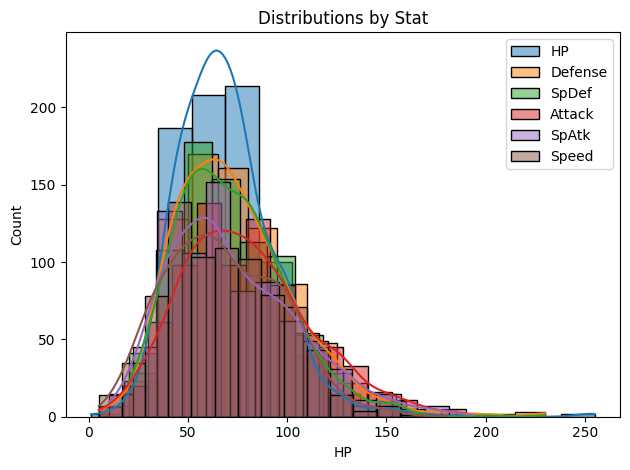

In [119]:
sns.histplot(df['HP'],kde=True, bins = 15,label = "HP"), sns.histplot(df['Defense'],kde = True, bins = 15,label = "Defense"), sns.histplot(df['SpDef'],kde=True, bins = 15,label="SpDef")
sns.histplot(df['Attack'],kde = True, bins = 15,label="Attack"), sns.histplot(df['SpAtk'],kde=True,bins=15,label="SpAtk")
sns.histplot(df['Speed'],kde=True,bins=15, label = "Speed")
plt.legend()
plt.title("Distributions by Stat")
plt.show()

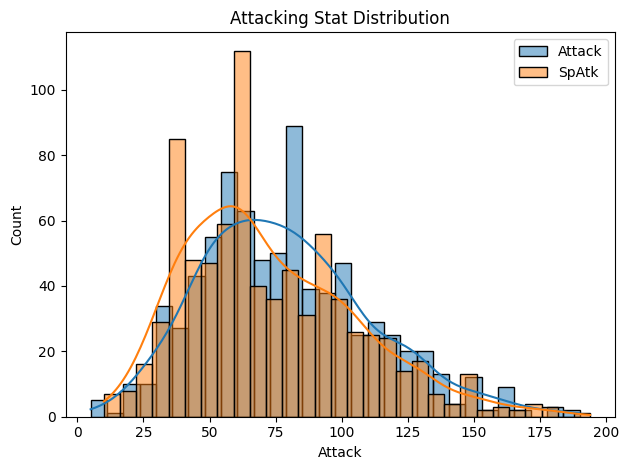

In [131]:
sns.histplot(df['Attack'],kde = True, bins = 30,label="Attack") 
sns.histplot(df['SpAtk'],kde=True,bins=30,label="SpAtk")
plt.legend()
plt.title("Attacking Stat Distribution")
plt.show()

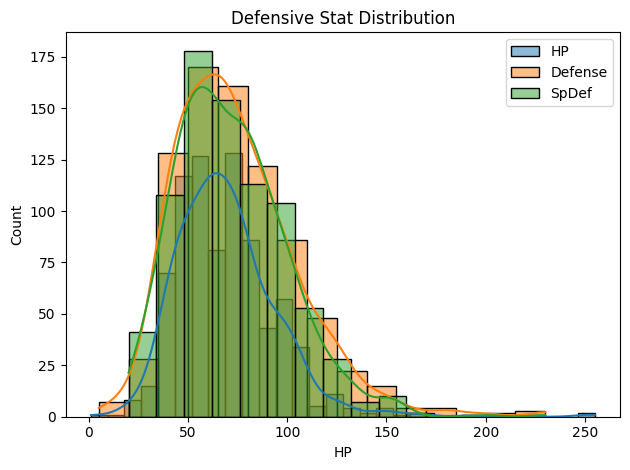

In [132]:
sns.histplot(df['HP'],kde=True, bins = 30,label = "HP"), sns.histplot(df['Defense'],kde = True, bins = 15,label = "Defense"), sns.histplot(df['SpDef'],kde=True, bins = 15,label="SpDef")
plt.legend()
plt.title("Defensive Stat Distribution")
plt.show()

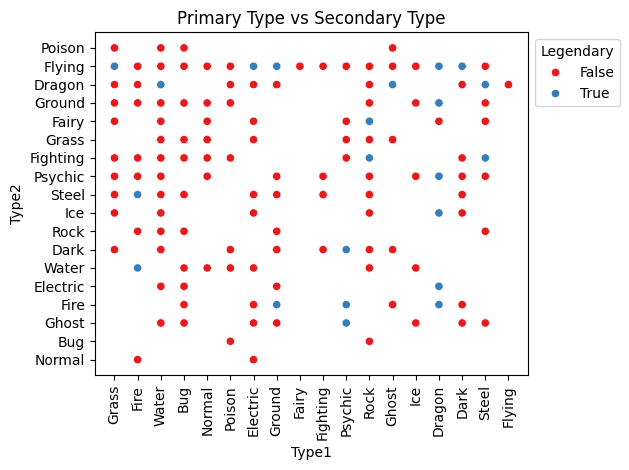

In [158]:
ax = sns.scatterplot(x=df['Type1'],y=df['Type2'],hue=df['Legendary'],palette="Set1")
ax.tick_params(axis='x', rotation=90)
plt.title("Primary Type vs Secondary Type")
sns.move_legend(ax,"upper left", bbox_to_anchor = (1,1))
plt.show()

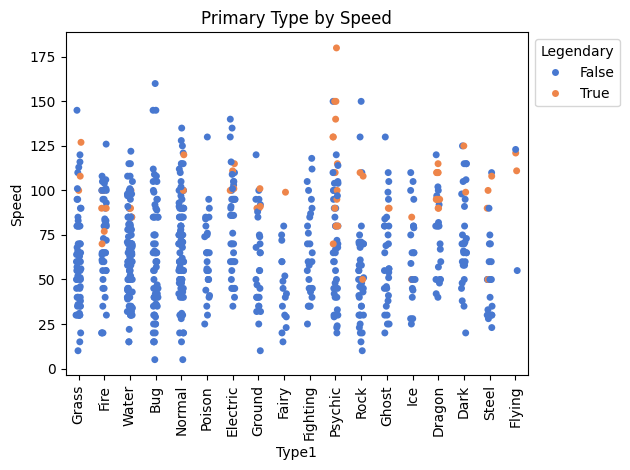

In [152]:
ax = sns.stripplot(x=df["Type1"],y=df["Speed"],hue = df["Legendary"],palette="muted")
ax.tick_params(axis='x', rotation=90)
sns.move_legend(ax,"upper left", bbox_to_anchor = (1,1))
plt.title("Primary Type by Speed")
plt.show()

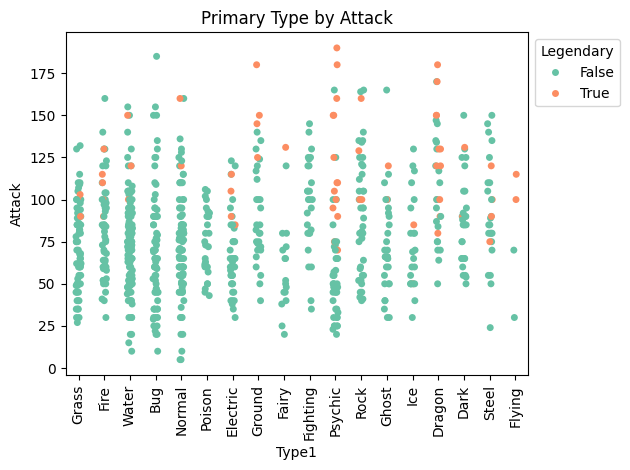

In [151]:
ax = sns.stripplot(x=df["Type1"],y=df["Attack"],hue = df["Legendary"],palette="Set2")
ax.tick_params(axis='x', rotation=90)
sns.move_legend(ax,"upper left", bbox_to_anchor = (1,1))
plt.title("Primary Type by Attack")
plt.show()

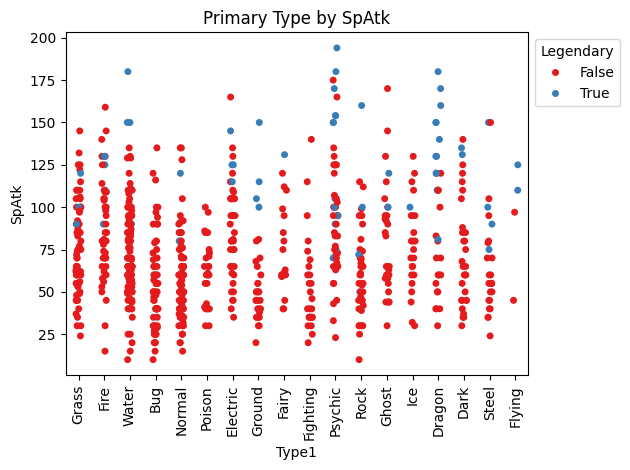

In [150]:
ax = sns.stripplot(x=df["Type1"],y=df["SpAtk"],hue = df["Legendary"],palette="Set1")
ax.tick_params(axis='x', rotation=90)
sns.move_legend(ax,"upper left", bbox_to_anchor = (1,1))
plt.title("Primary Type by SpAtk")
plt.show()

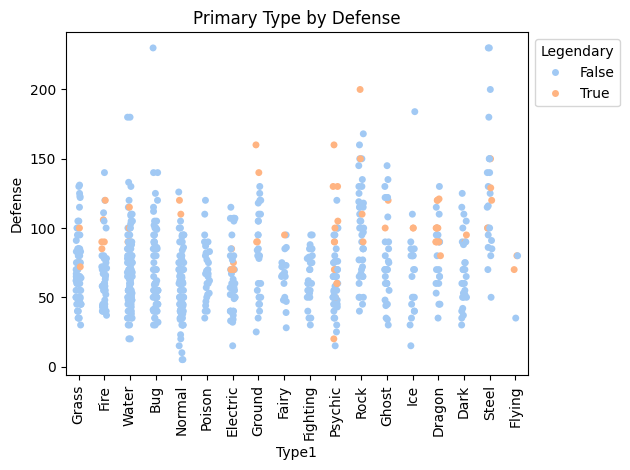

In [149]:
ax = sns.stripplot(x=df["Type1"],y=df["Defense"],hue = df["Legendary"],palette="pastel")
ax.tick_params(axis='x', rotation=90)
sns.move_legend(ax,"upper left", bbox_to_anchor = (1,1))
plt.title("Primary Type by Defense")
plt.show()

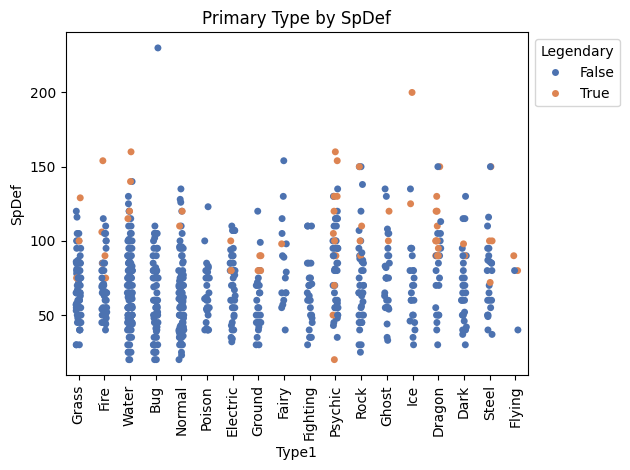

In [148]:
ax = sns.stripplot(x=df["Type1"],y=df["SpDef"],hue = df["Legendary"],palette="deep")
ax.tick_params(axis='x', rotation=90)
sns.move_legend(ax,"upper left", bbox_to_anchor = (1,1))
plt.title("Primary Type by SpDef")
plt.show()

Text(0.5, 1.0, 'Speed over Generations')

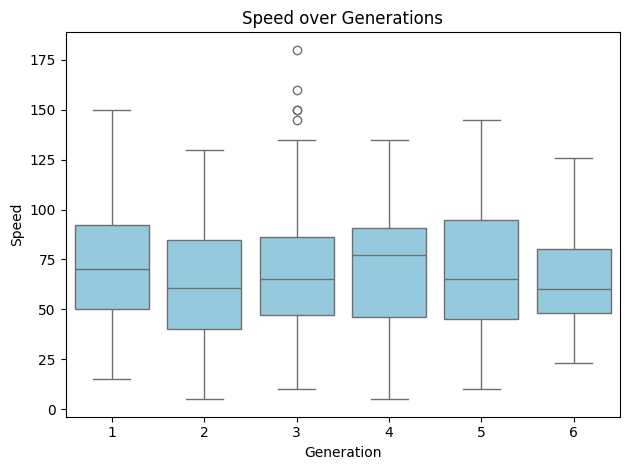

In [159]:
#is powercreep real? How do stats change over generations

sns.boxplot(x=df['Generation'],y = df['Speed'],color = "skyblue")
plt.title("Speed over Generations")

Text(0.5, 1.0, 'Attack by Generation')

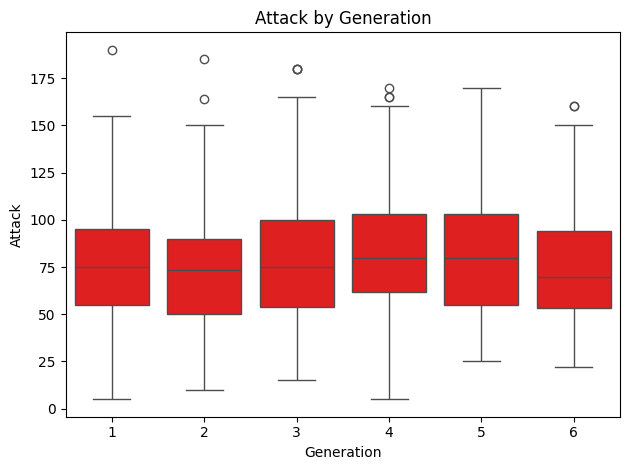

In [129]:
sns.boxplot(x=df['Generation'],y = df['Attack'],color="red")
plt.title("Attack by Generation")

Text(0.5, 1.0, 'SpAtk by Generation')

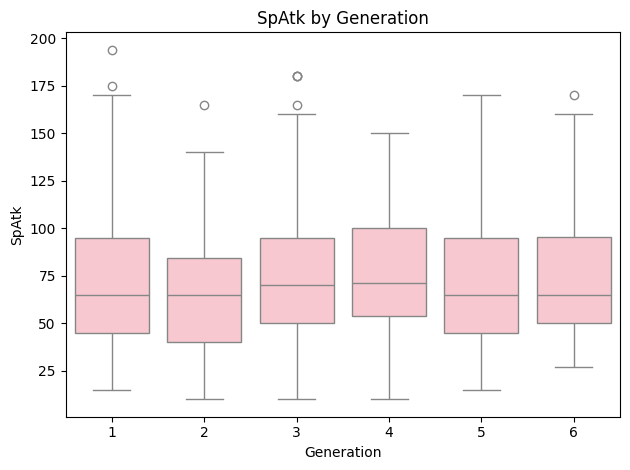

In [130]:
sns.boxplot(x=df['Generation'],y = df['SpAtk'],color="pink")
plt.title("SpAtk by Generation")


Text(0.5, 1.0, 'BST by Generation')

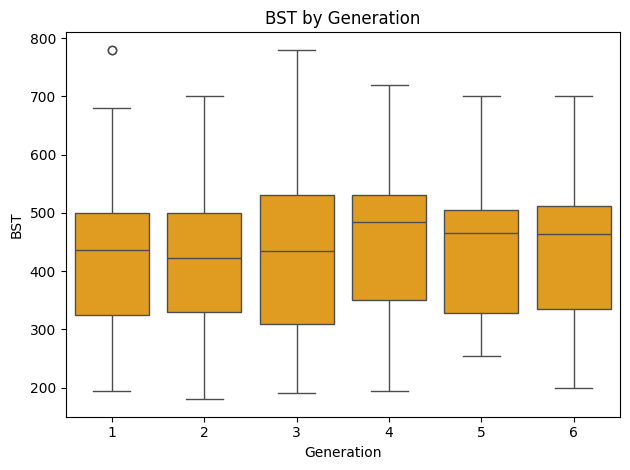

In [138]:
df['BST'] = df['HP'] + df['Attack'] + df ['SpAtk'] + df['SpDef']+df['Defense'] +df['Speed']

sns.boxplot(x=df['Generation'],y = df['BST'],color="orange")

plt.title("BST by Generation")

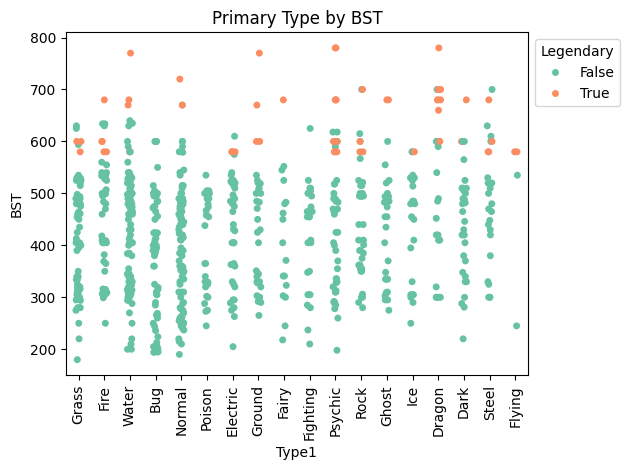

In [147]:
ax = sns.stripplot(x=df["Type1"],y=df["BST"],hue = df["Legendary"],palette="Set2")
ax.tick_params(axis='x', rotation=90)
plt.title("Primary Type by BST")
sns.move_legend(ax, "upper left", bbox_to_anchor=(1, 1))
plt.show()